In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline

In [3]:
df = pd.read_csv('../diabetes_prediction_dataset.csv')

In [4]:
df.head()

,gender,age,hypertension,heart_disease,smoking_history,bmi,HbA1c_level,blood_glucose_level,diabetes
0,Female,80.0,0,1,never,25.19,6.6,140,0
1,Female,54.0,0,0,No Info,27.32,6.6,80,0
2,Male,28.0,0,0,never,27.32,5.7,158,0
3,Female,36.0,0,0,current,23.45,5.0,155,0
4,Male,76.0,1,1,current,20.14,4.8,155,0


In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 9 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   gender               100000 non-null  str    
 1   age                  100000 non-null  float64
 2   hypertension         100000 non-null  int64  
 3   heart_disease        100000 non-null  int64  
 4   smoking_history      100000 non-null  str    
 5   bmi                  100000 non-null  float64
 6   HbA1c_level          100000 non-null  float64
 7   blood_glucose_level  100000 non-null  int64  
 8   diabetes             100000 non-null  int64  
dtypes: float64(3), int64(4), str(2)
memory usage: 6.9 MB


In [6]:
df.describe()

,age,hypertension,heart_disease,bmi,HbA1c_level,blood_glucose_level,diabetes
count,100000.000000,100000.00000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000
mean,41.885856,0.07485,0.039420,27.320767,5.527507,138.058060,0.085000
std,22.516840,0.26315,0.194593,6.636783,1.070672,40.708136,0.278883
min,0.080000,0.00000,0.000000,10.010000,3.500000,80.000000,0.000000
25%,24.000000,0.00000,0.000000,23.630000,4.800000,100.000000,0.000000
50%,43.000000,0.00000,0.000000,27.320000,5.800000,140.000000,0.000000
75%,60.000000,0.00000,0.000000,29.580000,6.200000,159.000000,0.000000
max,80.000000,1.00000,1.000000,95.690000,9.000000,300.000000,1.000000


In [7]:
df['diabetes'].value_counts(normalize=True)

diabetes
0    0.915
1    0.085
Name: proportion, dtype: float64

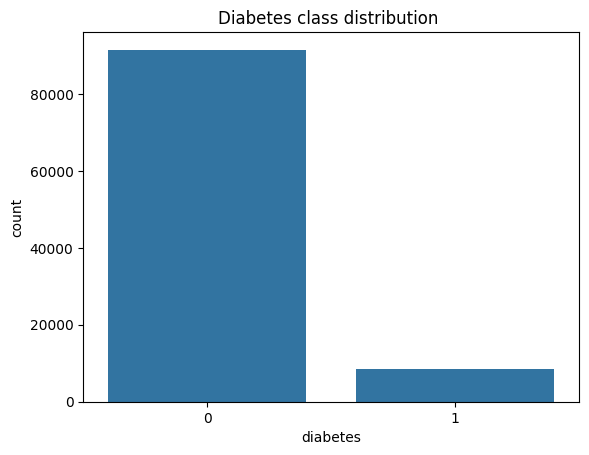

In [8]:
sns.countplot(x='diabetes', data=df)
plt.title('Diabetes class distribution ')
plt.show()

In [9]:
df['diabetes'].value_counts()

diabetes
0    91500
1     8500
Name: count, dtype: int64

In [11]:
print(df['gender'].value_counts())

gender
Female    58552
Male      41430
Other        18
Name: count, dtype: int64


In [12]:
df['smoking_history'].value_counts()

smoking_history
No Info        35816
never          35095
former          9352
current         9286
not current     6447
ever            4004
Name: count, dtype: int64

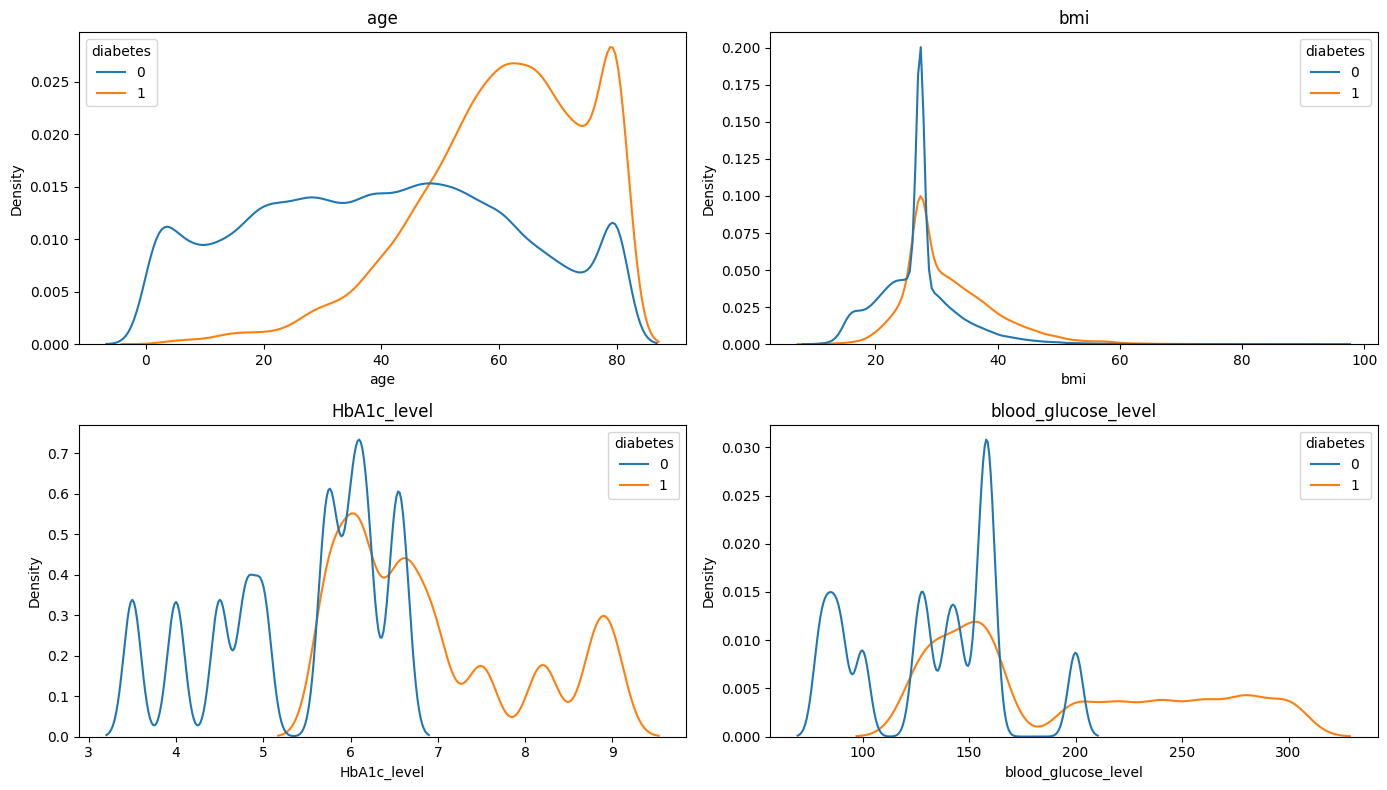

In [13]:
num_cols = ['age', 'bmi', 'HbA1c_level', 'blood_glucose_level']
fig, axes = plt.subplots(2, 2, figsize=(14, 8))

for ax, col in zip(axes.flat, num_cols):
    sns.kdeplot(data=df, x=col, hue='diabetes', common_norm=False, ax=ax)
    ax.set_title(col)

plt.tight_layout()
plt.show()


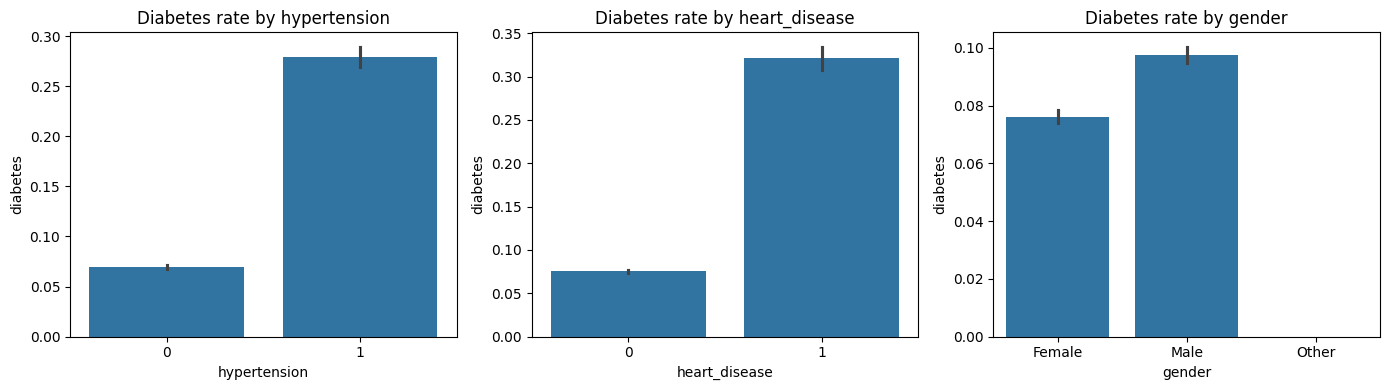

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, col in zip(axes, ['hypertension', 'heart_disease', 'gender']):
    sns.barplot(x=col, y='diabetes', data=df, ax=ax)
    ax.set_title(f"Diabetes rate by {col}")

plt.tight_layout()
plt.show()

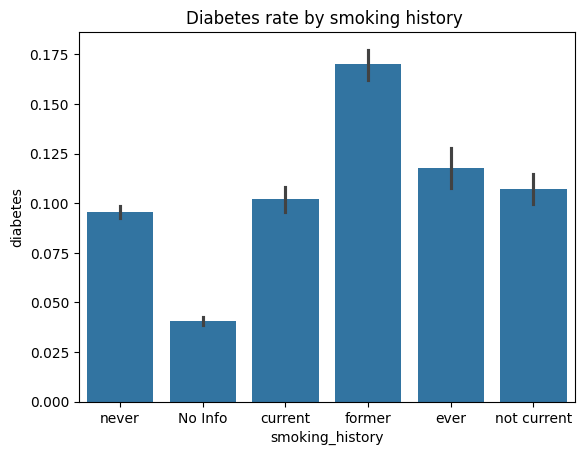

In [15]:
sns.barplot(x='smoking_history', y='diabetes', data=df)
plt.title('Diabetes rate by smoking history ')
plt.show()

 ## Correlation

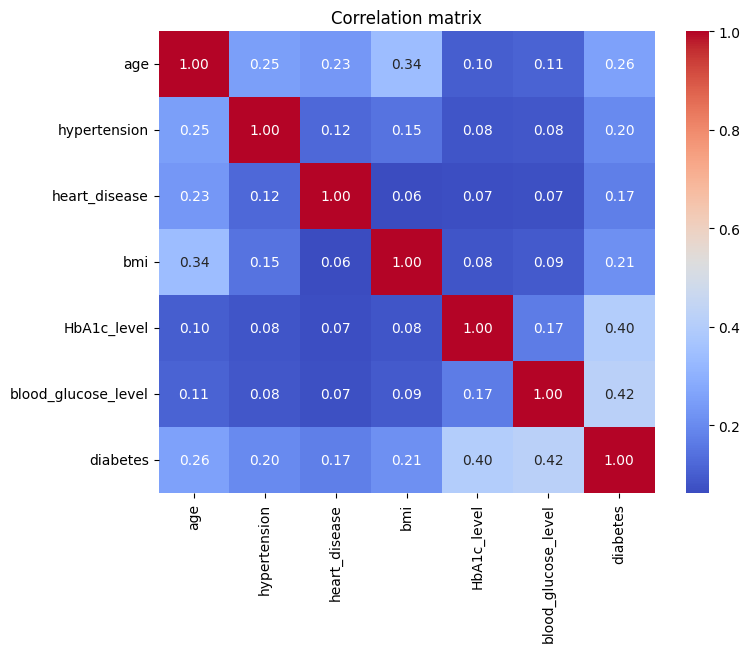

In [16]:
plt.figure(figsize=(8, 6))

sns.heatmap(df.select_dtypes(include=np.number).corr(),
            annot=True,
            fmt='.2f',
            cmap='coolwarm'
)

plt.title('Correlation matrix')
plt.show()

## Feature Engineering & encoding


In [17]:
df_model = pd.get_dummies(df, columns=['gender', 'smoking_history'], drop_first=True)

df_model.head()

,age,hypertension,heart_disease,bmi,HbA1c_level,blood_glucose_level,diabetes,gender_Male,gender_Other,smoking_history_current,smoking_history_ever,smoking_history_former,smoking_history_never,smoking_history_not current
0,80.0,0,1,25.19,6.6,140,0,False,False,False,False,False,True,False
1,54.0,0,0,27.32,6.6,80,0,False,False,False,False,False,False,False
2,28.0,0,0,27.32,5.7,158,0,True,False,False,False,False,True,False
3,36.0,0,0,23.45,5.0,155,0,False,False,True,False,False,False,False
4,76.0,1,1,20.14,4.8,155,0,True,False,True,False,False,False,False


In [18]:
X = df_model.drop('diabetes', axis=1)
y = df_model['diabetes']

X.shape, y.shape

((100000, 13), (100000,))

In [19]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

In [20]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [21]:
X_train.shape, X_test.shape

((80000, 13), (20000, 13))

In [22]:
from sklearn.tree import DecisionTreeClassifier

In [23]:
treeClassifier = DecisionTreeClassifier(class_weight='balanced',random_state=42)

treeClassifier.fit(X_train, y_train)

y_pred = treeClassifier.predict(X_test)
y_proba = treeClassifier.predict_proba(X_test)[:1]

print("Train Accuracy : ", round(treeClassifier.score(X_train,y_train), 4))

print("Test Accuracy: ", round(treeClassifier.score(X_test, y_test), 4))

Train Accuracy :  0.999
Test Accuracy:  0.9546


In [24]:
from sklearn.metrics import classification_report, roc_auc_score, confusion_matrix, accuracy_score

In [25]:
print(classification_report(y_test, y_pred))
print(roc_auc_score(y_test, y_pred))
print(confusion_matrix(y_test, y_pred))
print(accuracy_score(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.98      0.97      0.98     18300
           1       0.73      0.74      0.74      1700

    accuracy                           0.95     20000
   macro avg       0.85      0.86      0.86     20000
weighted avg       0.96      0.95      0.95     20000

0.8583622629379619
[[17831   469]
 [  438  1262]]
0.95465


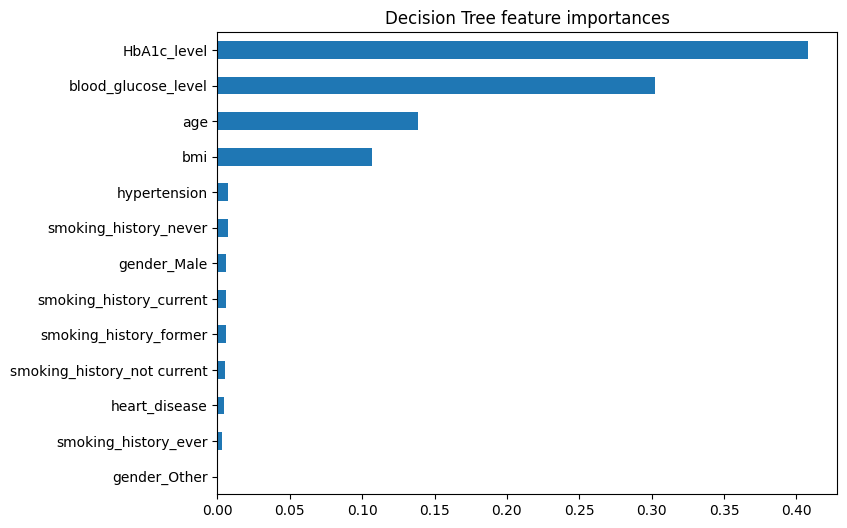

In [26]:
importances = pd.Series(treeClassifier.feature_importances_,
                        index=X.columns
).sort_values()
importances.plot(kind='barh',
                figsize=(8,6),
                title='Decision Tree feature importances'
)
plt.show()

In [27]:
from sklearn.tree import plot_tree


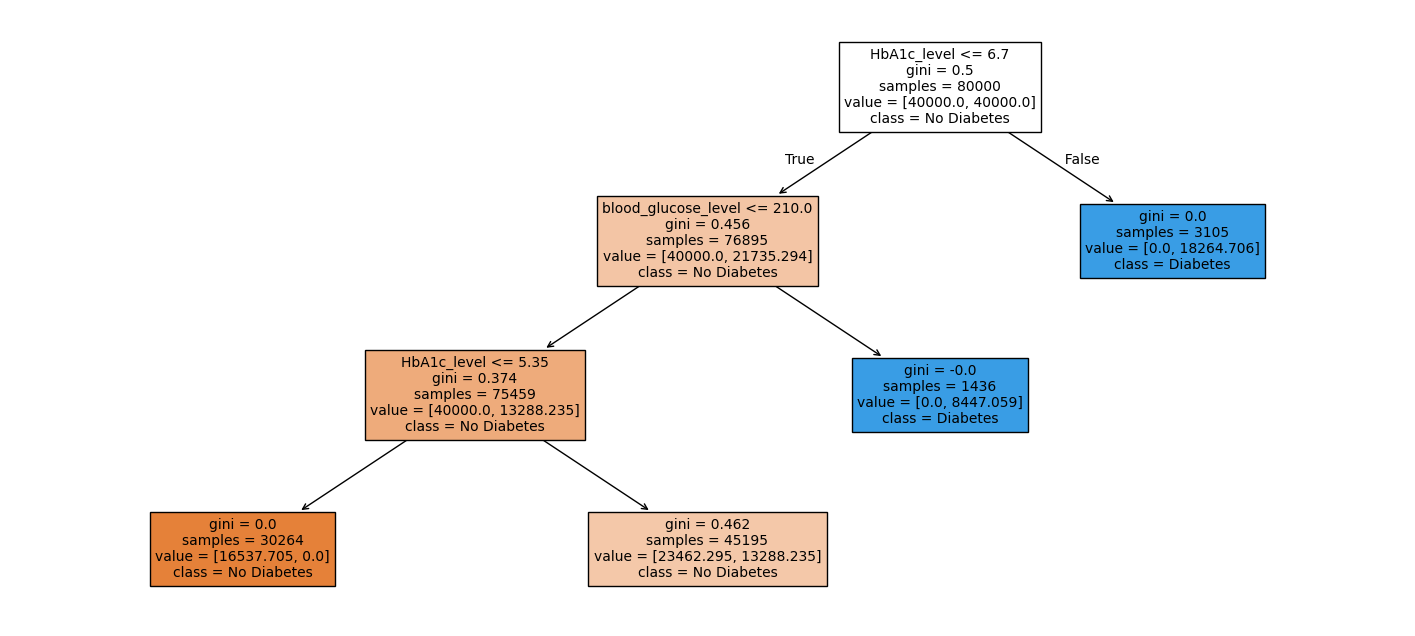

In [28]:
treeClassifier_small = DecisionTreeClassifier(max_depth=3,class_weight='balanced', random_state=42)

treeClassifier_small.fit(X_train, y_train)
plt.figure(figsize=(18, 8))
plot_tree(treeClassifier_small,
          feature_names=X.columns,
          class_names=['No Diabetes', 'Diabetes'],
          filled=True,
          fontsize=10)

plt.show()